# WH reference diagnostics over the Bloch sphere

For each pure qubit fiducial
$$|\psi(\theta,\phi)\rangle=\cos(\theta/2)|0\rangle
+e^{i\phi}\sin(\theta/2)|1\rangle,$$
build its Weyl–Heisenberg reference device and compare exact probabilities
with finite-shot local Cirq measurements. This notebook uses the current
`Measurement`, `CircuitSpec`, and `Experiment` APIs, with no cloud processor
or legacy task files.

Install the notebook dependencies with `pip install -e '.[notebooks]'`.
The defaults retain the original $20\times20$ grid and 50,000 shots **per
prepared orbit state** (1,600 circuits, 80 million total shots). Lower `N` or
`n_shots` for a faster exploratory run. Data and figures are saved under
`artifacts/full_bloch_sphere/` in the repository.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cirq_sic.analysis import stabilizer_renyi_entropy
from cirq_sic.measurements import build_measurement_circuit, wh_measurement
from cirq_sic.sics import SIC_P, load_sic_fiducial
from cirq_sic.workflow import CircuitSpec, Experiment, ExperimentResult

repo_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "cirq_sic").is_dir() and (p / "pyproject.toml").is_file()),
    None,
)
output_dir = (repo_root or Path.cwd()) / "artifacts" / "full_bloch_sphere"
image_dir = output_dir / "img"
image_dir.mkdir(parents=True, exist_ok=True)

d = 2
N = 20
n_shots = 50_000
seed = 2026
alpha = 2
cutoff = 50

thetas = np.linspace(0, np.pi, N)
phis = np.linspace(0, 2*np.pi, N)
# Every grid array is indexed [phi_index, theta_index]. Include both seam
# endpoints to close the plotting domain; their sampled data are independent.
Theta, Phi = np.meshgrid(thetas, phis, indexing="xy")
fiducials = np.stack([
    np.cos(Theta / 2).astype(complex),
    np.exp(1j * Phi) * np.sin(Theta / 2),
], axis=-1)

## Reference circuits and results

For every fiducial, prepare each of its four normalized WH orbit states and
measure the corresponding WH POVM. Rows of the resulting matrix label
measurement outcomes and columns label prepared states:
$$P_{ij}=\operatorname{Tr}(E_i\sigma_j)
=\frac{|\langle\psi_i|\psi_j\rangle|^2}{2}.$$

Use the general measurement builder: many fiducials on this grid have
rank-deficient reference matrices, which are valid measurements but cannot
be used for informationally complete tomography.

In [2]:
measurements = [wh_measurement(state) for state in fiducials.reshape(-1, d)]
specs = []
for k, measurement in enumerate(measurements):
    phi_index, theta_index = np.unravel_index(k, Theta.shape)
    for j, state in enumerate(measurement.states.T):
        built = build_measurement_circuit(measurement, state)
        specs.append(CircuitSpec(
            name=f"reference/{k}/{j}",
            circuit=built.circuit,
            qubit_order=built.qubit_order,
            measured_qubits=built.measured_qubits,
            key=built.measurement_key,
            num_outcomes=measurement.num_outcomes,
            metadata={"phi_index": int(phi_index), "theta_index": int(theta_index),
                      "prepared_outcome": j},
        ))

experiment = Experiment(
    specs,
    name="full_bloch_sphere_wh_reference",
    metadata={"dimension": d, "grid_size": N, "n_shots": n_shots, "seed": seed},
    arrays={"thetas": thetas, "phis": phis, "fiducials": fiducials},
)
print(f"Built {len(specs):,} circuits for {len(measurements)} fiducials.")

Built 1,600 circuits for 400 fiducials.


In [3]:
exact_result = experiment.simulate()
print("Exact reference simulation complete.")
sampled_result = experiment.run(repetitions=n_shots, seed=seed)
print(f"Sampled {n_shots:,} shots per orbit state.")

experiment.save(output_dir / "experiment.json")
exact_result.save(output_dir / "exact_result.json")
sampled_result.save(output_dir / "sampled_result.json")

Exact reference simulation complete.


Sampled 50,000 shots per orbit state.


In [4]:
def reference_matrices(result):
    matrices = []
    for k in range(len(measurements)):
        columns = [result[f"reference/{k}/{j}"] for j in range(d**2)]
        if any(column.leakage > 1e-8 for column in columns):
            raise ValueError("Reference readout has probability in padded outcomes.")
        matrices.append(np.column_stack([column.valid for column in columns]))
    return np.asarray(matrices).reshape(Theta.shape + (d**2, d**2))


P = reference_matrices(sampled_result)
exact_P = reference_matrices(exact_result)
analytic_P = np.asarray([
    np.abs(m.states.conj().T @ m.states)**2 / d for m in measurements
]).reshape(exact_P.shape)

np.testing.assert_allclose(exact_P, analytic_P, atol=1e-10)
np.testing.assert_allclose(exact_P.sum(axis=-2), 1, atol=1e-10)
np.testing.assert_allclose(P.sum(axis=-2), 1, atol=1e-10)
np.testing.assert_allclose(exact_P[0], exact_P[-1], atol=1e-10)

# The current JSON result format must preserve the observed frequencies.
restored = ExperimentResult.load(output_dir / "sampled_result.json")
np.testing.assert_array_equal(reference_matrices(restored), P)
print("Circuit probabilities agree with analytic WH overlaps; persistence passes.")

Circuit probabilities agree with analytic WH overlaps; persistence passes.


## Entropy and LTP deformation

Retain the original natural-log convention (nats) and pseudoinverse diagnostic:
$$M_\alpha=\frac{1}{1-\alpha}\log\sum_i P_{i0}^{\alpha}-\log2,
\qquad Q=\|P^+-I\|_F.$$
For a pure qubit fiducial, the first reference column is its WH
characteristic distribution, so this entropy equals the state-based
stabilizer Rényi entropy. Sampled values are plug-in estimates and can have
finite-shot bias.

The Moore–Penrose pseudoinverse $P^+$ is defined even at singular reference
matrices. At these points it is not an inverse Born-rule transform; its finite
value can differ sharply from nearby invertible matrices. The deformation
plots cap values at `cutoff` for display only. The full arrays are retained.

In [5]:
def calculate_magic(matrix, order):
    probabilities = np.asarray(matrix)[..., :, 0]
    return np.log(np.sum(probabilities**order, axis=-1)) / (1-order) - np.log(d)


def calculate_ltp_deformation(matrix):
    return np.linalg.norm(np.linalg.pinv(matrix) - np.eye(d**2), axis=(-2, -1))


magic = calculate_magic(P, alpha)
exact_magic = calculate_magic(exact_P, alpha)
deform = calculate_ltp_deformation(P)
exact_deform = calculate_ltp_deformation(exact_P)
max_magic = np.log((1 + (d-1)*(d+1)**(1-alpha)) / d) / (1-alpha)
sic_quantumness = calculate_ltp_deformation(SIC_P(d))

# Check the entire entropy map independently from the input states.
state_entropy = np.asarray([
    stabilizer_renyi_entropy(state, alpha=alpha, basis="wh", base=np.e)
    for state in fiducials.reshape(-1, d)
]).reshape(Theta.shape)
np.testing.assert_allclose(exact_magic, state_entropy, atol=1e-10)
np.testing.assert_allclose(exact_magic[:, [0, -1]], 0, atol=1e-10)
assert np.all(exact_magic <= max_magic + 1e-10)

# The SIC need not lie exactly on the angular grid, so test it separately.
sic = wh_measurement(load_sic_fiducial(d))
sic_reference = np.abs(sic.states.conj().T @ sic.states)**2 / d
np.testing.assert_allclose(sic_reference, SIC_P(d), atol=1e-8)
np.testing.assert_allclose(calculate_magic(sic_reference, alpha), max_magic, atol=1e-8)
np.testing.assert_allclose(calculate_ltp_deformation(sic_reference), sic_quantumness, atol=1e-8)
print(f"SIC benchmarks: M_{alpha} = {max_magic:.6f} nats; Q = {sic_quantumness:.6f}")

np.savez_compressed(
    output_dir / "diagnostics.npz", thetas=thetas, phis=phis,
    P=P, exact_P=exact_P, magic=magic, exact_magic=exact_magic,
    deform=deform, exact_deform=exact_deform,
)

SIC benchmarks: M_2 = 0.405465 nats; Q = 3.464102


In [6]:
def contour_map(values, title, colorbar_label, filename, *, levels):
    if values.shape != Theta.shape:
        raise ValueError("Map must have shape (number of phis, number of thetas).")
    fig, ax = plt.subplots(figsize=(6, 6))
    cs = ax.contourf(Theta, Phi, values, levels=levels, extend="both")
    fig.colorbar(cs, ax=ax, label=colorbar_label)
    ax.set(title=title, xlabel=r"$\theta$", ylabel=r"$\phi$")
    ax.set_xticks([0, np.pi/2, np.pi], ["0", r"$\pi/2$", r"$\pi$"])
    ax.set_yticks([0, np.pi, 2*np.pi], ["0", r"$\pi$", r"$2\pi$"])
    fig.tight_layout()
    fig.savefig(image_dir / filename)
    plt.show()
    return fig


# Shared scales allow comparison between exact and finite-shot maps.
entropy_levels = np.linspace(0, max_magic, 16)
deformation_levels = np.linspace(0, cutoff, 16)

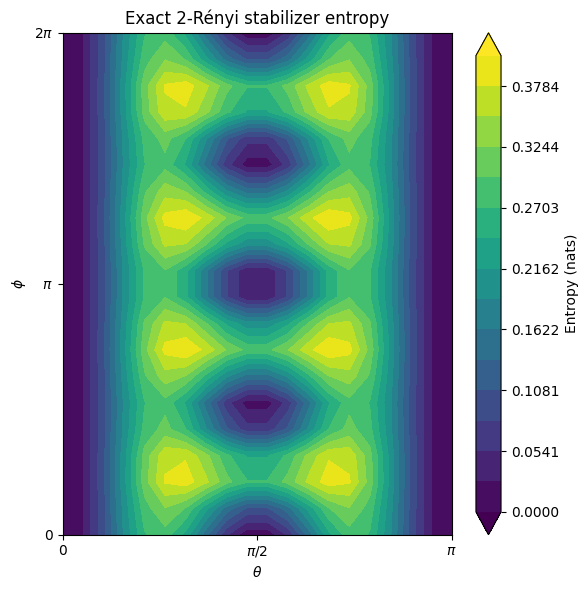

In [7]:
fig_exact_magic = contour_map(
    exact_magic, f"Exact {alpha}-Rényi stabilizer entropy",
    "Entropy (nats)", "bloch_exact_magic.pdf", levels=entropy_levels,
)

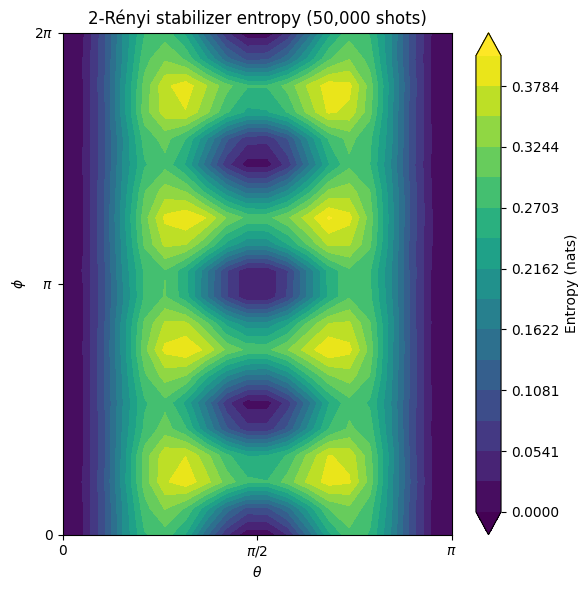

In [8]:
fig_magic = contour_map(
    magic, f"{alpha}-Rényi stabilizer entropy ({n_shots:,} shots)",
    "Entropy (nats)", "bloch_magic.pdf", levels=entropy_levels,
)

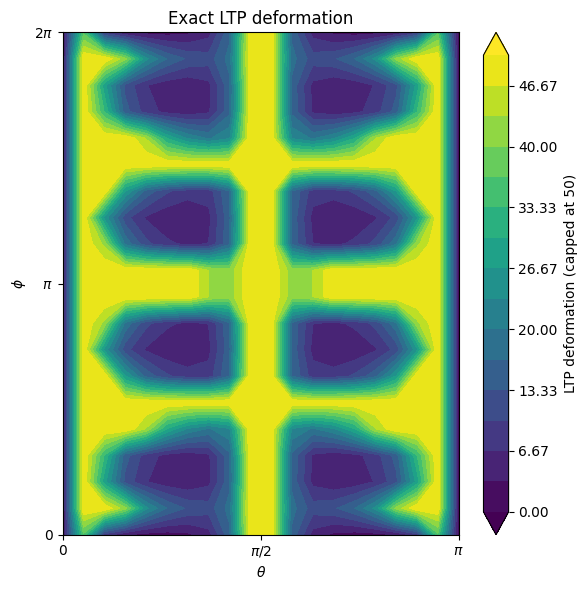

In [9]:
fig_exact_deform = contour_map(
    np.minimum(exact_deform, cutoff), "Exact LTP deformation",
    f"LTP deformation (capped at {cutoff})", "bloch_exact_deform.pdf",
    levels=deformation_levels,
)

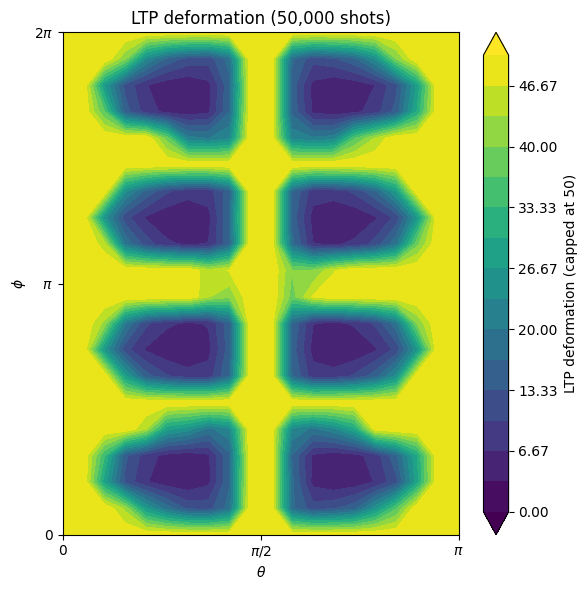

Saved experiment, results, diagnostic arrays, and four PDFs to /home/heyredhat/Documents/cirq_sic/artifacts/full_bloch_sphere


In [10]:
fig_deform = contour_map(
    np.minimum(deform, cutoff), f"LTP deformation ({n_shots:,} shots)",
    f"LTP deformation (capped at {cutoff})", "bloch_deform.pdf",
    levels=deformation_levels,
)
print(f"Saved experiment, results, diagnostic arrays, and four PDFs to {output_dir}")